This notebook provides a benchmarking of the surrogate + SAEM implementation on a well-known data set, the **theophylline** data.

The study was reported by Upton and analyzed by Boeckmann et al. (1994).


In [19]:
import pandas as pd
import torch
from plotnine import *

from vpop_calibration.api import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
def analytical_model(d, v, ka, cl, t):
    """Analytical expression of a 1 compartment PK model

    Args:
        t: time in h
        d: Dose in mg
        v: Distribution volume in mL
        ka: Absorption rate constant in mL/h
        cl: Clearance rate constant in mL/h

    Returns:
        y: Predicted concentration
    """
    ke = cl / v
    y = d * ka / (v * (ka - ke)) * (torch.exp(-ke * t) - torch.exp(-ka * t))
    return y


struct_model = StructuralAnalytical(analytical_model, ["concentration"])

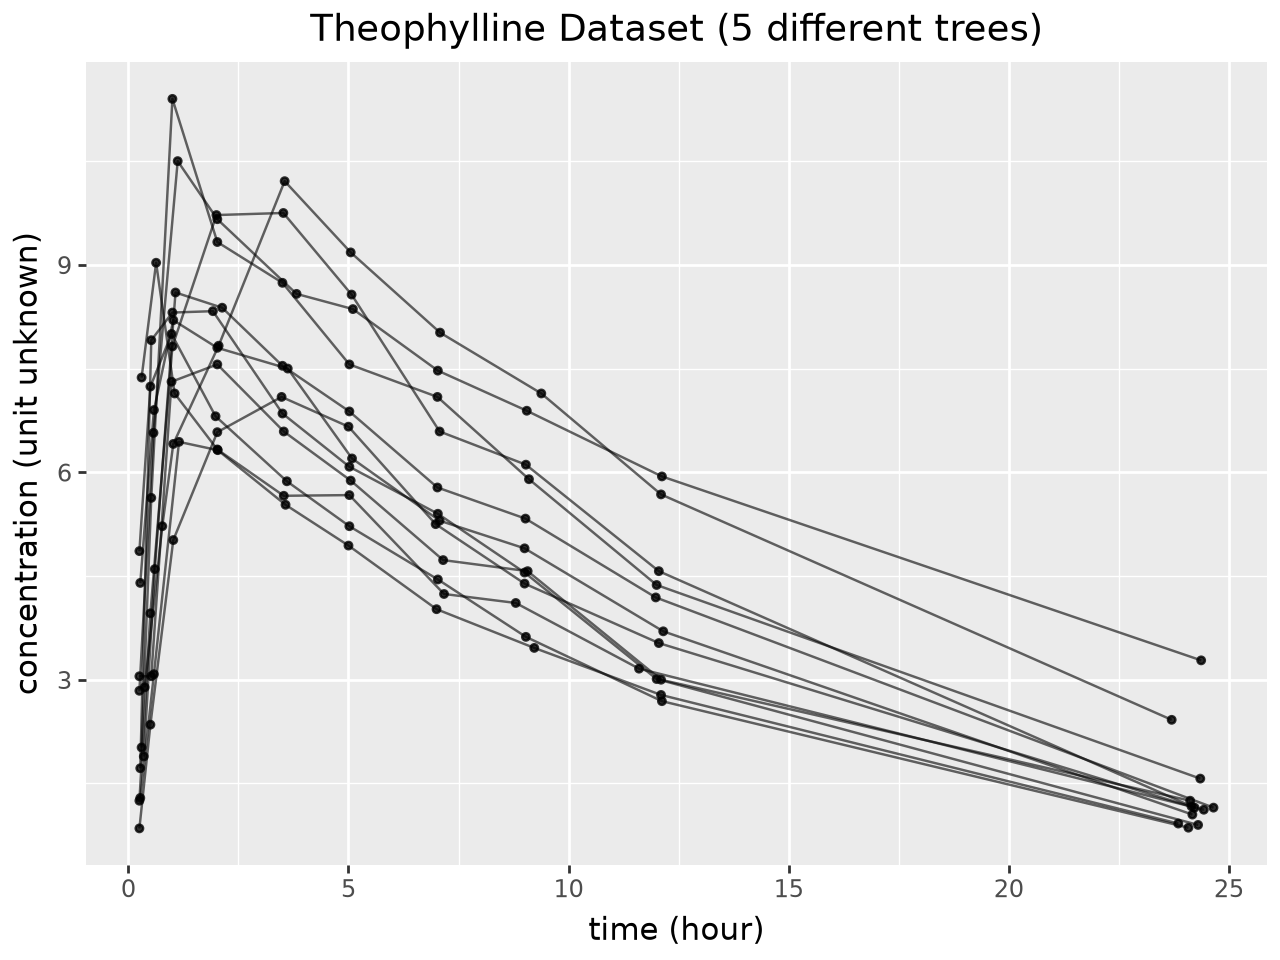

In [21]:
theophylline_data_url = "https://monolixsuite.slp-software.com/__attachments/a_2acdcb24e3aa515c4da35ea2dd93e97ce8ef9661c6086afb40937ba697a30bca/theophylline_data.txt?cb=bf00f82a5318f623eea61d62202d9b0e"

df = pd.read_csv(theophylline_data_url, sep="\t")
patients_df = df.copy()
patients_df = patients_df.loc[df["AMT"] != "."]
patients_df.loc[:, "d"] = patients_df.apply(
    lambda r: float(r["AMT"]) * r["WEIGHT"], axis=1
)
patients_df = patients_df.rename(columns={"ID": "id", "WEIGHT": "bw"})[
    ["id", "d", "bw"]
]
obs_df = (
    df.loc[df["AMT"] == "."]
    .rename(columns={"ID": "id", "CONC": "value", "TIME": "time"})[
        ["id", "time", "value"]
    ]
    .astype({"value": "float"})
)
obs_df["output_name"] = "concentration"
obs_df["protocol_arm"] = "identity"
obs_df = obs_df.merge(patients_df, on=["id"])
(
    ggplot(obs_df, aes(x="time", y="value", group="id"))
    + geom_line(alpha=0.6)
    + geom_point(size=1, alpha=0.8)
    + theme(legend_position="none")
    + labs(
        title="Theophylline Dataset (5 different trees)",
        x="time (hour)",
        y="concentration (unit unknown)",
    )
)

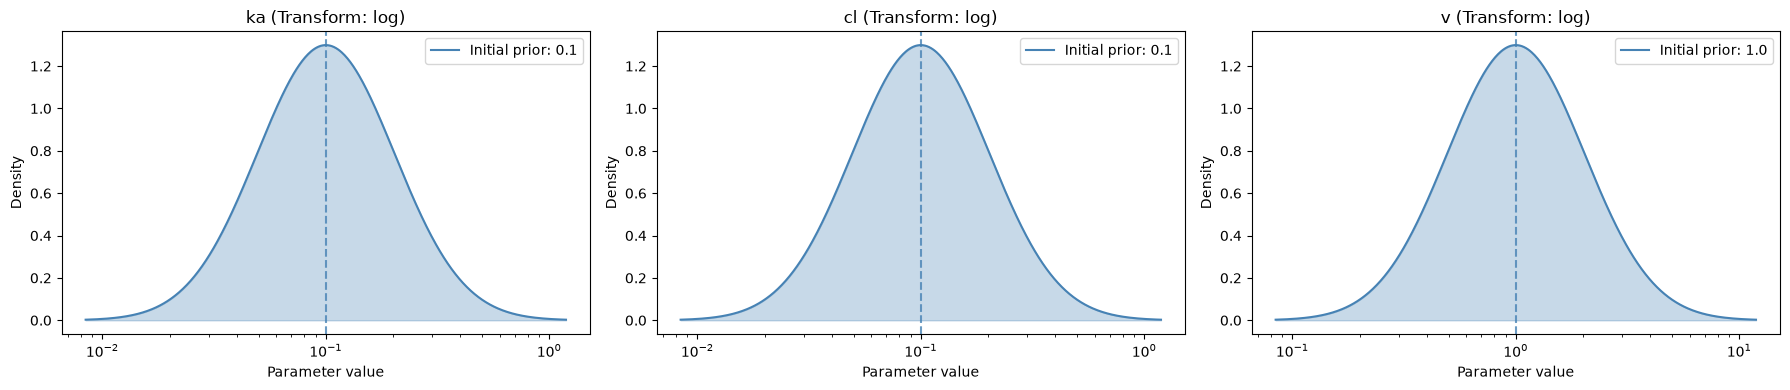

  0%|          | 0/320 [00:00<?, ?it/s]

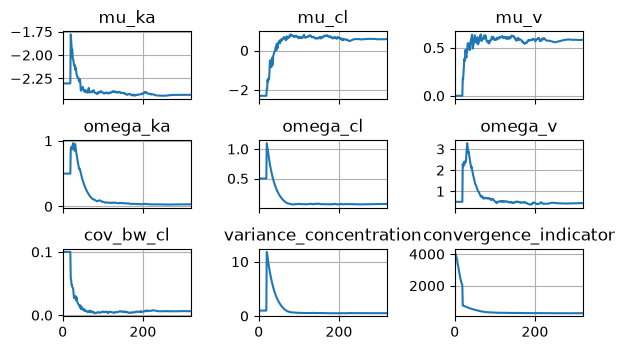

In [22]:
model_params = {
    "pdu": {
        "ka": {"prior": 0.1, "prior_omega": 0.5},
        "cl": {
            "prior": 0.1,
            "prior_omega": 0.5,
            "covariates": {"bw": {"coef_name": "cov_bw_cl", "prior": 0.1}},
        },
        "v": {"prior": 1.0, "prior_omega": 0.5},
    },
    "pdk": ["d"],
    "error_model": {
        "concentration": {"error_type": "additive", "initial_variance": 1.0}
    },
}
config = Config(
    nlme=NlmeConfigDict(nb_chains=10),
    saem=SaemConfigDict(
        nb_iter_burnin=20,
        nb_iter_learning=200,
        nb_iter_smoothing=100,
        logging=False,
        logging_frequency=50,
        progress_bars=True,
        live_plot=True,
    ),
)
nlme_model = NlmeModel(
    structural_model=struct_model, df=obs_df, input_params=model_params, config=config
)
nlme_model.initial_estimates.plot_distribution()
nlme_model.optimizer.run()

Simulating population:   0%|          | 0/100 [00:00<?, ?it/s]

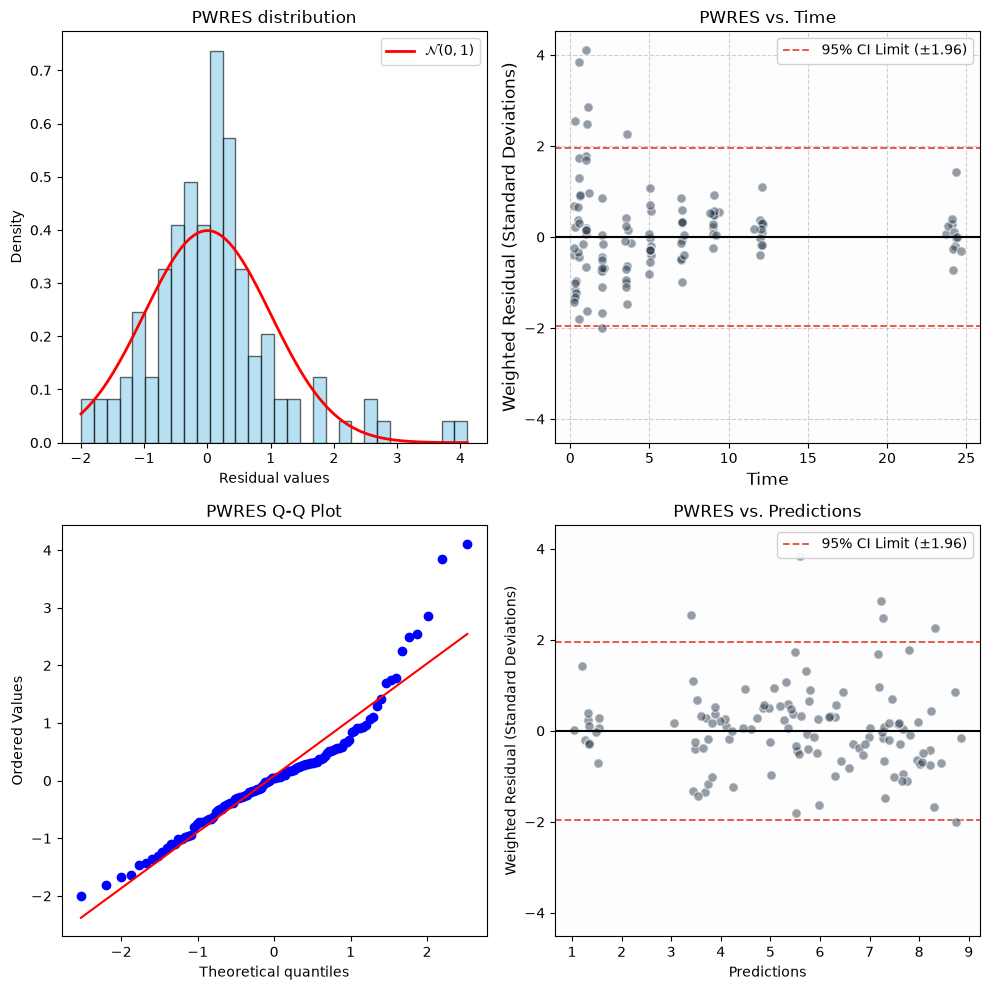

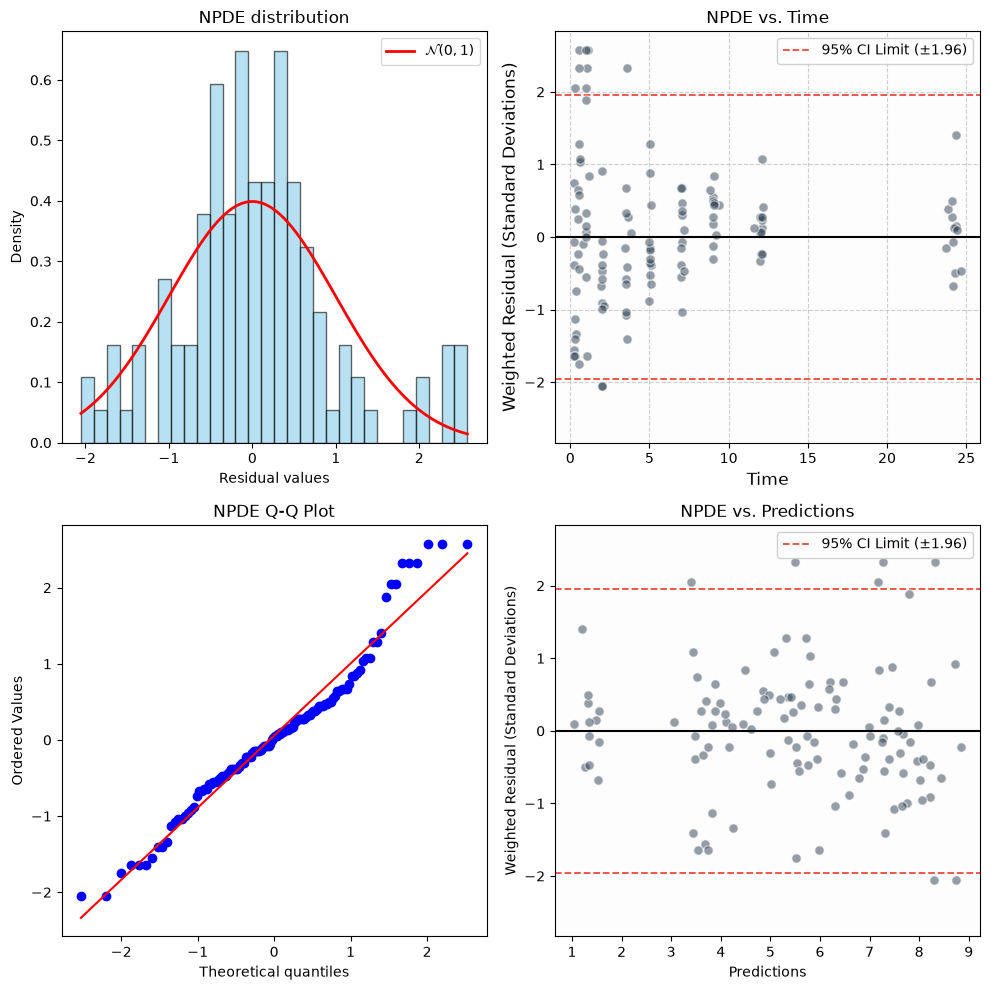

In [23]:
nlme_model.diagnostics.compute_population_diagnostics(nb_samples=100)
nlme_model.plot.weighted_residuals("pwres")
nlme_model.plot.weighted_residuals("npde")

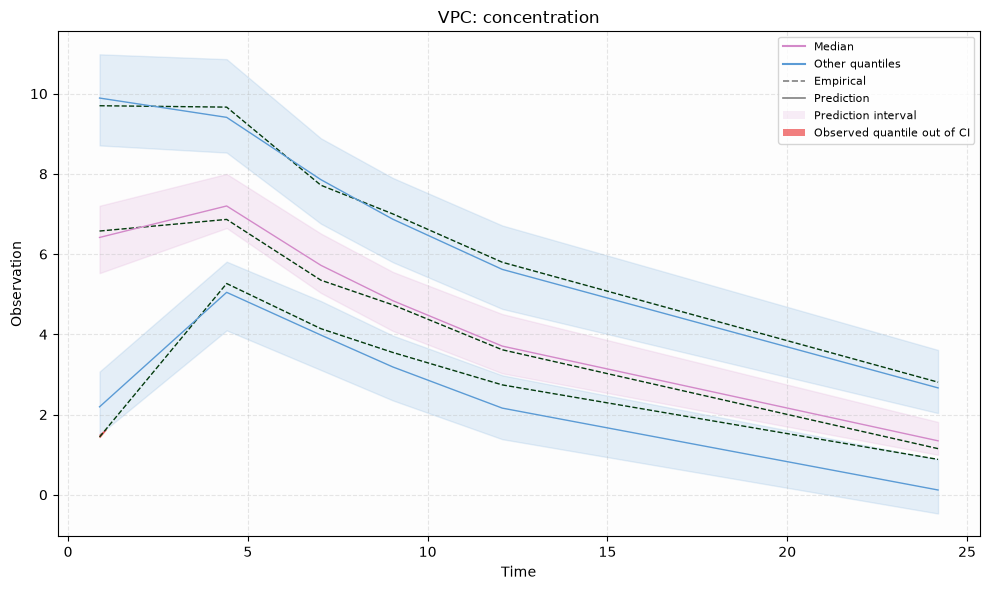

In [24]:
nlme_model.plot.vpc()

1100 conditional samples already in cache, running the sampler for 10 more iterations.


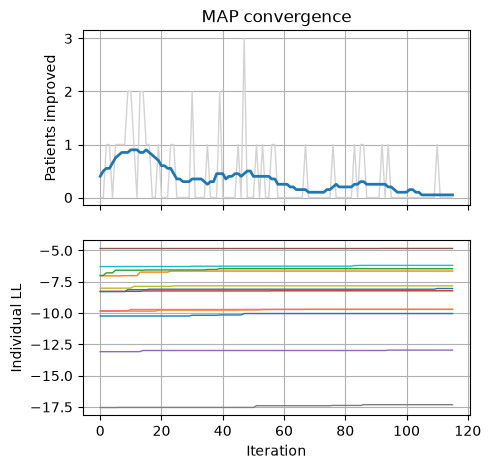

  0%|          | 0/10 [00:00<?, ?it/s]

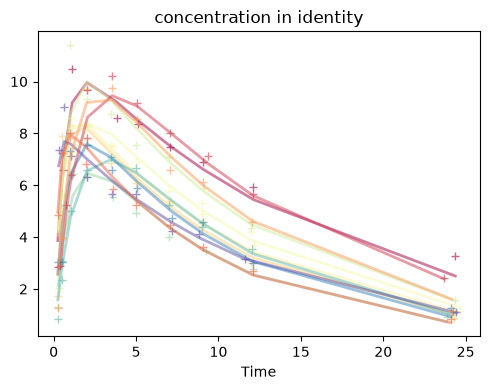

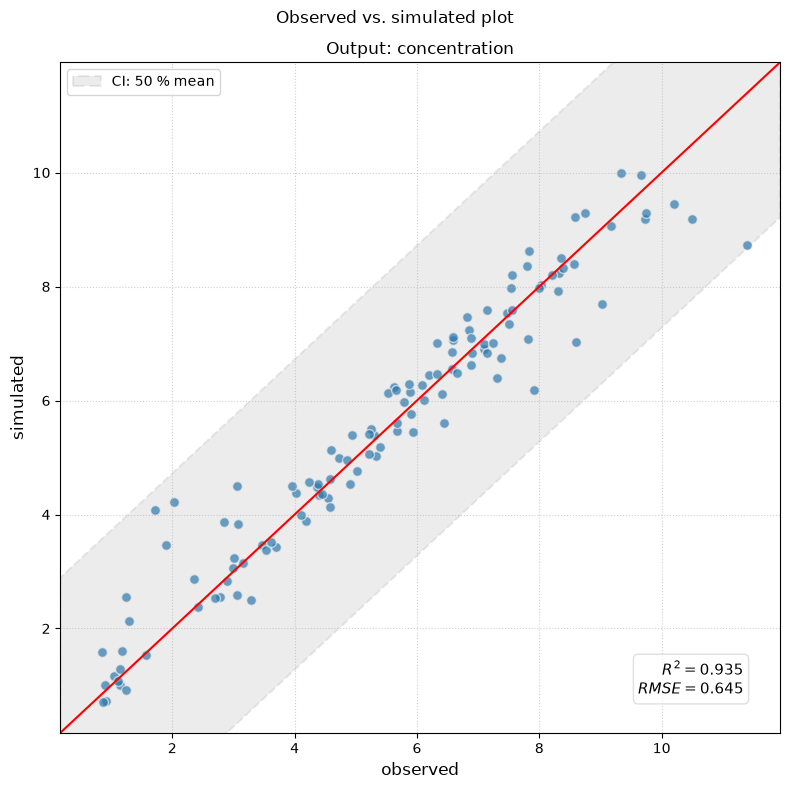

In [32]:
nlme_model.sample_conditional_distribution(100)
nlme_model.plot.map_estimates()
nlme_model.plot.map_estimates_gof()

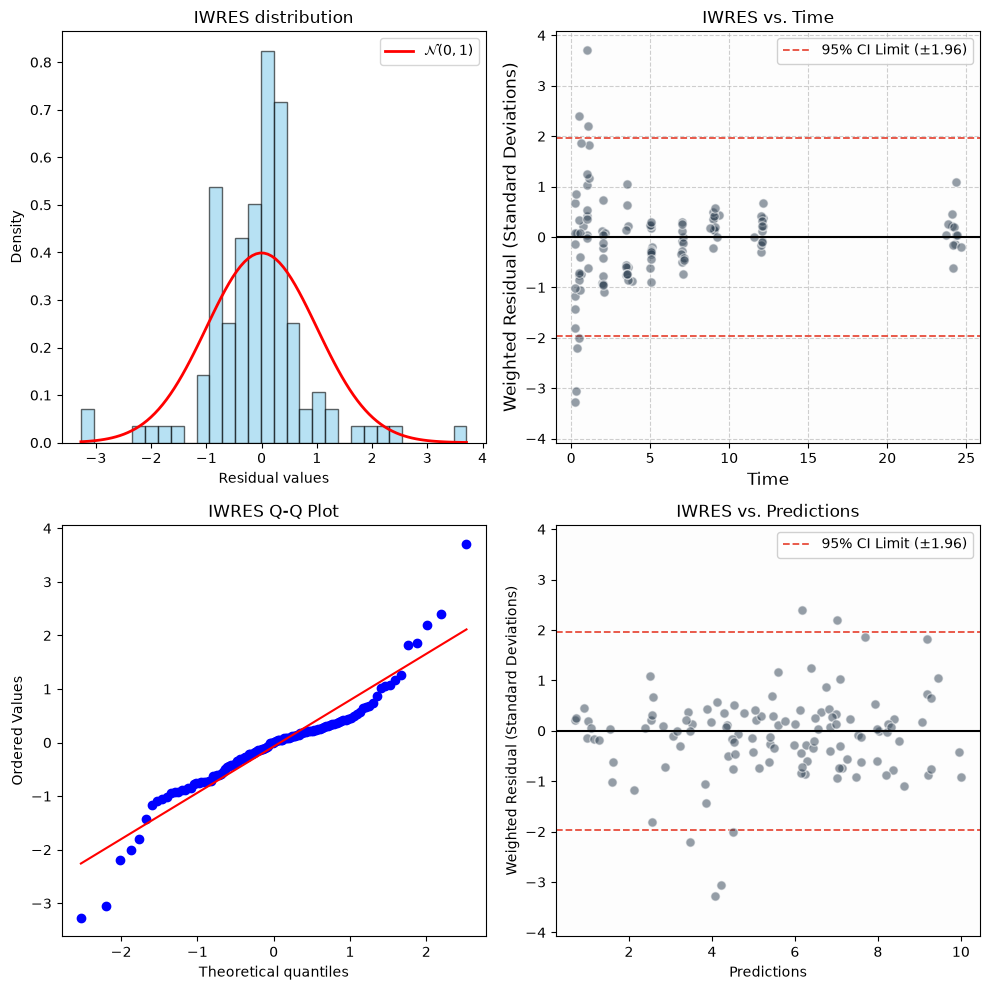

In [33]:
nlme_model.plot.weighted_residuals("iwres")

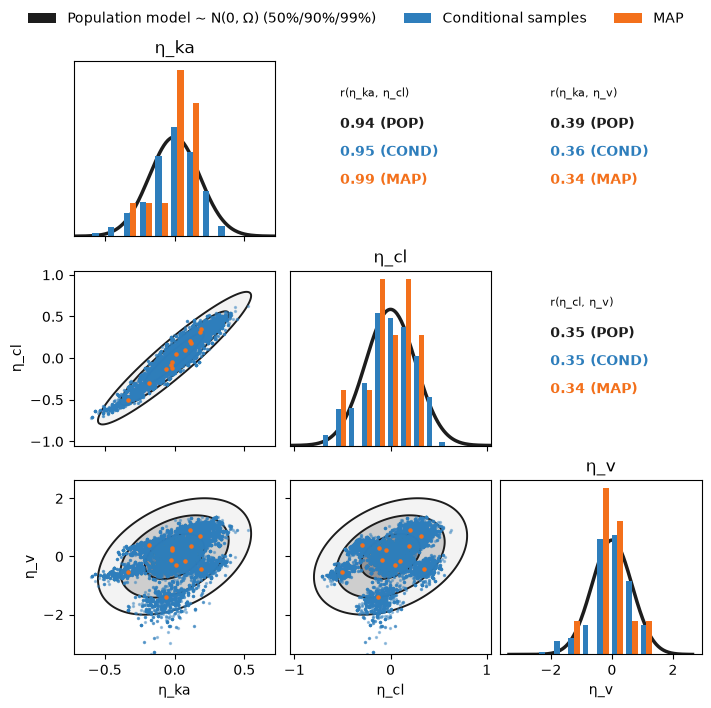

In [34]:
nlme_model.plot.conditional_codistributions(figsize=[7, 7])

In [28]:
df = nlme_model.diagnostics.report_shrinkage(nb_samples=100)
display(df.round(1))

,ka,cl,v
shrinkage(%),16.6,4.7,5.0


In [29]:
nlme_model.diagnostics.compute_log_likelihood_importance_sampling(
    nb_proposal_samples=1000
)
print(
    f"Observed-data log-likelihood estimate, -2LL = {-2*nlme_model.diagnostics.importance_sampler.log_lik:.2f}"
)

Importance sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Observed-data log-likelihood estimate, -2LL = 332.31
